<a href="https://colab.research.google.com/github/ArifMesi/Calculator-Android-Compose/blob/main/Pratikum_ML_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image, ImageOps
#!pip install rembg
import os
#from rembg import remove
import pandas as pd
import numpy as np
import cv2
import os
import csv
from skimage.feature import graycomatrix, graycoprops
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sb

In [ ]:
!pip install xgboost
import xgboost as xgb

Prprocessing Citra

In [1]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

Ekstraksi Fitur

In [ ]:
path = '/content/drive/MyDrive/02. Penelitian/embrio/good'
data = os.listdir(path)

rataR = []
rataG = []
rataB = []
rataH = []
rataS = []
rataV = []
ratagray = []
stand = []
luas = []
perimeter = []
contrast = []
dissimilarity = []
homogeneity = []
energy = []
correlation = []
label = []

for gbr in data:
    gbr_read = cv2.imread(os.path.join(path, gbr))
    gbr_rgb = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2RGB)
    (R, G, B) = cv2.split(gbr_rgb)
    meanR = np.mean(R)
    rataR.append(meanR)
    meanG = np.mean(G)
    rataG.append(meanG)
    meanB = np.mean(B)
    rataB.append(meanB)

    gbr_hsv = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2HSV)
    H = gbr_hsv[:, :, 0]
    S = gbr_hsv[:, :, 1]
    V = gbr_hsv[:, :, 2]
    meanH = np.mean(H)
    rataH.append(meanH)
    meanS = np.mean(S)
    rataS.append(meanS)
    meanV = np.mean(V)
    rataV.append(meanV)

    gbr_gray = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2GRAY)
    rata = np.mean(gbr_gray)
    ratagray.append(rata)
    standar = np.std(gbr_gray)
    stand.append(standar)


    # Ekstraksi Fitur Bentuk
    _, thresh = cv2.threshold(gbr_gray, 127, 255, 0)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contours) > 0:
        contour = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(contour)
        perimeter_val = cv2.arcLength(contour, True)
    else:
        area = 0
        perimeter_val = 0

    luas.append(area)
    perimeter.append(perimeter_val)

    # Ekstraksi Fitur Tekstur (GLCM)
    glcm = graycomatrix(gbr_gray, [1], [0], 256, symmetric=True, normed=True)
    contrast_val = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity_val = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogeneity_val = graycoprops(glcm, 'homogeneity')[0, 0]
    energy_val = graycoprops(glcm, 'energy')[0, 0]
    correlation_val = graycoprops(glcm, 'correlation')[0, 0]

    contrast.append(contrast_val)
    dissimilarity.append(dissimilarity_val)
    homogeneity.append(homogeneity_val)
    energy.append(energy_val)
    correlation.append(correlation_val)

    Jenis_embrio = '0'
    label.append(Jenis_embrio)

data1 = pd.DataFrame(rataR, columns=['Mean-R'])
data2 = pd.DataFrame(rataG, columns=['Mean-G'])
data3 = pd.DataFrame(rataB, columns=['Mean-B'])
data4 = pd.DataFrame(rataH, columns=['Mean-H'])
data5 = pd.DataFrame(rataV, columns=['Mean-V'])
data6 = pd.DataFrame(rataS, columns=['Mean-s'])
data7 = pd.DataFrame(ratagray, columns=['Mean-Gray'])
data8 = pd.DataFrame(stand, columns=['Standar-Deviasi'])
data9 = pd.DataFrame(luas, columns=['Luas'])
data10 = pd.DataFrame(perimeter, columns=['Perimeter'])
data11 = pd.DataFrame(contrast, columns=['Contrast'])
data12 = pd.DataFrame(dissimilarity, columns=['Dissimilarity'])
data13 = pd.DataFrame(homogeneity, columns=['Homogeneity'])
data14 = pd.DataFrame(energy, columns=['Energy'])
data15 = pd.DataFrame(correlation, columns=['Correlation'])
data16 = pd.DataFrame(label, columns=['Klasifikasi Embrio'])

listdata1 = [data1, data2, data3, data4, data5, data6, data7, data8, data9,
             data10, data11, data12, data13, data14, data15, data16]
gabung1 = pd.concat(listdata1, axis=1)


In [ ]:
path = '/content/drive/MyDrive/02. Penelitian/embrio/not_good'
data = os.listdir(path)

rataR = []
rataG = []
rataB = []
rataH = []
rataS = []
rataV = []
ratagray = []
stand = []
luas = []
perimeter = []
contrast = []
dissimilarity = []
homogeneity = []
energy = []
correlation = []
label = []

for gbr in data:
    gbr_read = cv2.imread(os.path.join(path, gbr))
    gbr_rgb = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2RGB)
    (R, G, B) = cv2.split(gbr_rgb)
    meanR = np.mean(R)
    rataR.append(meanR)
    meanG = np.mean(G)
    rataG.append(meanG)
    meanB = np.mean(B)
    rataB.append(meanB)

    gbr_hsv = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2HSV)
    H = gbr_hsv[:, :, 0]
    S = gbr_hsv[:, :, 1]
    V = gbr_hsv[:, :, 2]
    meanH = np.mean(H)
    rataH.append(meanH)
    meanS = np.mean(S)
    rataS.append(meanS)
    meanV = np.mean(V)
    rataV.append(meanV)

    gbr_gray = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2GRAY)
    rata = np.mean(gbr_gray)
    ratagray.append(rata)
    standar = np.std(gbr_gray)
    stand.append(standar)


    # Ekstraksi Fitur Bentuk
    _, thresh = cv2.threshold(gbr_gray, 127, 255, 0)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contours) > 0:
        contour = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(contour)
        perimeter_val = cv2.arcLength(contour, True)
    else:
        area = 0
        perimeter_val = 0

    luas.append(area)
    perimeter.append(perimeter_val)

    # Ekstraksi Fitur Tekstur (GLCM)
    glcm = graycomatrix(gbr_gray, [1], [0], 256, symmetric=True, normed=True)
    contrast_val = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity_val = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogeneity_val = graycoprops(glcm, 'homogeneity')[0, 0]
    energy_val = graycoprops(glcm, 'energy')[0, 0]
    correlation_val = graycoprops(glcm, 'correlation')[0, 0]

    contrast.append(contrast_val)
    dissimilarity.append(dissimilarity_val)
    homogeneity.append(homogeneity_val)
    energy.append(energy_val)
    correlation.append(correlation_val)

    Jenis_embrio = '1'
    label.append(Jenis_embrio)

data1 = pd.DataFrame(rataR, columns=['Mean-R'])
data2 = pd.DataFrame(rataG, columns=['Mean-G'])
data3 = pd.DataFrame(rataB, columns=['Mean-B'])
data4 = pd.DataFrame(rataH, columns=['Mean-H'])
data5 = pd.DataFrame(rataV, columns=['Mean-V'])
data6 = pd.DataFrame(rataS, columns=['Mean-s'])
data7 = pd.DataFrame(ratagray, columns=['Mean-Gray'])
data8 = pd.DataFrame(stand, columns=['Standar-Deviasi'])
data9 = pd.DataFrame(luas, columns=['Luas'])
data10 = pd.DataFrame(perimeter, columns=['Perimeter'])
data11 = pd.DataFrame(contrast, columns=['Contrast'])
data12 = pd.DataFrame(dissimilarity, columns=['Dissimilarity'])
data13 = pd.DataFrame(homogeneity, columns=['Homogeneity'])
data14 = pd.DataFrame(energy, columns=['Energy'])
data15 = pd.DataFrame(correlation, columns=['Correlation'])
data16 = pd.DataFrame(label, columns=['Klasifikasi Embrio'])

listdata1 = [data1, data2, data3, data4, data5, data6, data7, data8, data9,
             data10, data11, data12, data13, data14, data15, data16]
gabung2 = pd.concat(listdata1, axis=1)


In [ ]:

listdata = [gabung1, gabung2]
data_embrio = pd.concat(listdata, ignore_index=True)
data_embrio.to_csv("ekstrasi-fitur-embrio.csv", index=False)

print("tahap preprocessing telah selsai dibuat")

tahap preprocessing telah selsai dibuat


In [ ]:
data_embrio.head()

,Mean-R,Mean-G,Mean-B,Mean-H,Mean-V,Mean-s,Mean-Gray,Standar-Deviasi,Luas,Perimeter,Contrast,Dissimilarity,Homogeneity,Energy,Correlation,Klasifikasi Embrio
0,160.028793,163.134613,162.535629,76.782104,168.669083,21.551163,162.136459,35.653251,64844.0,1124.852812,209.909099,8.633670,0.261673,0.036497,0.917641,0
1,170.353439,170.914612,164.473312,65.727768,174.919662,23.390533,170.008270,39.239429,64027.5,1303.605119,545.267310,14.253983,0.207888,0.044769,0.823280,0
2,168.082550,168.282013,155.231064,39.171860,170.120255,24.732559,166.742050,31.658928,64941.0,1043.798989,129.220665,7.242325,0.261099,0.049440,0.935666,0
3,181.335252,183.735365,172.394707,49.939038,185.208258,20.235000,181.747055,18.189463,209950.0,1834.000000,45.386380,3.854955,0.353874,0.070464,0.931483,0
4,175.255798,169.834274,168.348389,84.670258,177.697906,22.260422,171.290237,36.360182,64973.0,1057.455844,475.850429,12.202849,0.252275,0.050141,0.820526,0


In [ ]:
data_embrio

,Mean-R,Mean-G,Mean-B,Mean-H,Mean-V,Mean-s,Mean-Gray,Standar-Deviasi,Luas,Perimeter,Contrast,Dissimilarity,Homogeneity,Energy,Correlation,Klasifikasi Embrio
0,160.028793,163.134613,162.535629,76.782104,168.669083,21.551163,162.136459,35.653251,64844.0,1124.852812,209.909099,8.633670,0.261673,0.036497,0.917641,0
1,170.353439,170.914612,164.473312,65.727768,174.919662,23.390533,170.008270,39.239429,64027.5,1303.605119,545.267310,14.253983,0.207888,0.044769,0.823280,0
2,168.082550,168.282013,155.231064,39.171860,170.120255,24.732559,166.742050,31.658928,64941.0,1043.798989,129.220665,7.242325,0.261099,0.049440,0.935666,0
3,181.335252,183.735365,172.394707,49.939038,185.208258,20.235000,181.747055,18.189463,209950.0,1834.000000,45.386380,3.854955,0.353874,0.070464,0.931483,0
4,175.255798,169.834274,168.348389,84.670258,177.697906,22.260422,171.290237,36.360182,64973.0,1057.455844,475.850429,12.202849,0.252275,0.050141,0.820526,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1427,169.256382,171.410000,165.969217,68.769480,175.927607,23.215043,170.158034,30.778452,139014.0,1640.509666,175.513289,7.355534,0.290307,0.043014,0.907532,1
1428,160.078384,162.556000,164.263641,82.392227,168.277267,17.941422,162.019272,27.972565,65025.0,1020.000000,162.625551,7.379565,0.312406,0.060085,0.896331,1
1429,163.471436,162.860840,161.712051,79.186264,169.805511,25.858627,162.915680,43.280569,65025.0,1020.000000,429.758624,12.074035,0.227619,0.044163,0.885551,1
1430,165.933426,159.892639,160.901581,92.102188,169.114441,26.115494,161.813812,44.834424,64638.0,1242.793937,629.062240,16.252344,0.179667,0.033874,0.843872,1


Pengolahan Model untuk Klasifikasi

Split Dependent (Target/Label) Independent (atribut) Value

In [ ]:
#skenario W
#x = def_Kopra.iloc[:,0:8].values
#y = def_Kopra.iloc[:,[-1]].values
#skenario B
#x = def_Kopra.iloc[:,8:10].values
#y = def_Kopra.iloc[:,[-1]].values
#skenario T
#x = def_Kopra.iloc[:,10:15].values
#y = def_Kopra.iloc[:,[-1]].values
#Skenario W dan B
#x = def_Kopra.iloc[:,0:10].values
#y = def_Kopra.iloc[:,[-1]].values
#Skenario W dan T
#x = def_Kopra.iloc[:,0:13].values
#y = def_Kopra.iloc[:,[-1]].values
#Skenario B dan T
#x = def_Kopra.iloc[:,8:15].values
#y = def_Kopra.iloc[:,[-1]].values
#Skenario W,B,dan T
x = data_embrio.iloc[:,0:15].values
y = data_embrio.iloc[:,[-1]].values

In [ ]:
y = y.reshape(len(y))

Feature Scaling

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x

array([[0.430406  , 0.37168885, 0.2763532 , ..., 0.1491403 , 0.0658203 ,
        0.77283244],
       [0.53475147, 0.4637114 , 0.29376034, ..., 0.0768553 , 0.10086215,
        0.5095663 ],
       [0.51180085, 0.43257277, 0.21073278, ..., 0.14836871, 0.12065281,
        0.82312271],
       ...,
       [0.46519888, 0.36845063, 0.2689546 , ..., 0.10337328, 0.09829499,
        0.68330309],
       [0.49008085, 0.33334248, 0.26167375, ..., 0.0389285 , 0.05470667,
        0.56701716],
       [0.5475153 , 0.44564728, 0.32045047, ..., 0.08984254, 0.06056595,
        0.523392  ]])

Split Data Testing dan Data Training

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.1,random_state=0)

# Klasifikasi dengan RF

In [ ]:
# Model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


# Klasifikasi dengan XGB

In [ ]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


# Convert y to numeric if it's not already
if isinstance(y, pd.Series) and y.dtype == 'object':  # Check if y is a pandas Series and of object type
    y = y.astype(int)
else:  # If y is not a pandas Series or not of object type, use LabelEncoder
    le = LabelEncoder()
    y = le.fit_transform(y)


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=0)


xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', n_estimators=100).fit(x_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:04:19] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


**Klasifikasi Dengan K-NN**

In [ ]:
knn = KNeighborsClassifier(n_neighbors=3,metric='euclidean').fit(x_train,y_train)
knn

KNeighborsClassifier(metric='euclidean', n_neighbors=3)

# Penggabungan RF dan XGB

In [ ]:
# Membuat ensemble dengan Voting Classifier
ensemble_model = VotingClassifier(
    estimators=[('rf', rf_model), ('xgb', xgb_model), ('knn', knn)],
    voting='hard'  # 'soft' untuk probabilitas rata-rata, 'hard' untuk prediksi mayoritas
)

In [ ]:
# Melatih model ensemble
ensemble_model.fit(x_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:05:58] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


VotingClassifier(estimators=[('rf', RandomForestClassifier(random_state=42)),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='mlogloss',
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow...
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=100, n_jobs=None,
                                            num_parallel_tree=None, ...)),
                             ('knn',
                              KNeighborsClassifier(metric='euclidean',
                                                   n_neighbors=3))])

**Integral sugeno**

In [ ]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 20.1 MB/s eta 0:00:00


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

# --- Prediksi dari masing-masing model ---
y_pred_rf = rf_model.predict(x_test)
y_pred_xgb = xgb_model.predict(x_test)
y_pred_knn = knn.predict(x_test)

# Pastikan tipe data integer
y_pred_rf = y_pred_rf.astype(int)
y_pred_xgb = y_pred_xgb.astype(int)
y_pred_knn = y_pred_knn.astype(int)

# --- Hitung akurasi tiap model ---
accuracy_rf = accuracy_score(y_test, y_pred_rf)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

# --- Simpan fuzzy measure ---
fuzzy_measures = {
    'rf': accuracy_rf,
    'xgb': accuracy_xgb,
    'knn': accuracy_knn
}

# --- Urutkan berdasarkan akurasi (fuzzy density) ---
sorted_fuzzy_measures = sorted(fuzzy_measures.items(), key=lambda item: item[1])
g = np.array([fm[1] for fm in sorted_fuzzy_measures])

print("Fuzzy measures (accuracies):", fuzzy_measures)
print("Sorted fuzzy measures:", sorted_fuzzy_measures)
print("Fuzzy densities (g_i):", g)

# --- Gabungkan prediksi model ---
# Bentuk matriks prediksi: baris = sampel, kolom = model
pred_matrix = np.vstack([y_pred_knn, y_pred_rf, y_pred_xgb]).T

# --- Fungsi Fuzzy Sugeno Integral ---
def sugeno_integral(pred_row, g):
    # Urutkan nilai prediksi dan fuzzy density sesuai nilai prediksi
    sorted_idx = np.argsort(pred_row)
    pred_sorted = pred_row[sorted_idx]
    g_sorted = g[sorted_idx]

    # Hitung nilai integral Sugeno: max_i (min(pred_i, g_i))
    sugeno_value = np.max(np.minimum(pred_sorted, g_sorted))
    return sugeno_value

# --- Hitung hasil ensemble dengan Sugeno integral ---
fuzzy_outputs = np.array([sugeno_integral(row, g) for row in pred_matrix])

# --- Konversi hasil menjadi label 0/1 ---
# Jika output fuzzy ≥ 0.5 maka prediksi = 1, jika < 0.5 maka = 0
fuzzy_predictions = (fuzzy_outputs >= 0.5).astype(int)

# --- Evaluasi hasil ensemble ---
fuzzy_accuracy = accuracy_score(y_test, fuzzy_predictions)
print("\nAkurasi Ensemble (Fuzzy Sugeno Integral):", fuzzy_accuracy)


Fuzzy measures (accuracies): {'rf': 0.9375, 'xgb': 0.9097222222222222, 'knn': 0.7916666666666666}
Sorted fuzzy measures: [('knn', 0.7916666666666666), ('xgb', 0.9097222222222222), ('rf', 0.9375)]
Fuzzy densities (g_i): [0.79166667 0.90972222 0.9375    ]

Akurasi Ensemble (Fuzzy Sugeno Integral): 0.9166666666666666


# Prediksi

In [ ]:
y_prediksi = rf_model.predict(x_test)

Akurasi

In [ ]:
#Metrik Akurasi
# Membuat DataFrame untuk data uji
# Reshape y_prediksi and y_test to be 1-dimensional if they are not
y_prediksi = y_prediksi.reshape(-1)
y_test = y_test.reshape(-1)

df_prediksi = pd.DataFrame({'Prediksi': y_prediksi, 'Label Sebenarnya': y_test})

# Mencetak citra yang terprediksi benar dan salah
for index, row in df_prediksi.iterrows():
    if row['Prediksi'] == row['Label Sebenarnya']:
        print(f"Citra ke-{index+1}: Prediksi benar")
    else:
        print(f"Citra ke-{index+1}: Prediksi salah")

# Menghitung jumlah prediksi yang benar
jumlah_benar = (df_prediksi['Prediksi'] == df_prediksi['Label Sebenarnya']).sum()
jumlah_seluruh = len(df_prediksi)

# Menghitung dan mencetak nilai akurasi
nilai_akurasi = jumlah_benar / jumlah_seluruh
print("Jumlah prediksi yang benar:", jumlah_benar)
print("Jumlah seluruh prediksi:", jumlah_seluruh)
print("Nilai akurasi:", nilai_akurasi)

Citra ke-1: Prediksi benar
Citra ke-2: Prediksi benar
Citra ke-3: Prediksi benar
Citra ke-4: Prediksi benar
Citra ke-5: Prediksi benar
Citra ke-6: Prediksi benar
Citra ke-7: Prediksi benar
Citra ke-8: Prediksi benar
Citra ke-9: Prediksi benar
Citra ke-10: Prediksi benar
Citra ke-11: Prediksi benar
Citra ke-12: Prediksi benar
Citra ke-13: Prediksi benar
Citra ke-14: Prediksi benar
Citra ke-15: Prediksi benar
Citra ke-16: Prediksi benar
Citra ke-17: Prediksi benar
Citra ke-18: Prediksi benar
Citra ke-19: Prediksi benar
Citra ke-20: Prediksi benar
Citra ke-21: Prediksi benar
Citra ke-22: Prediksi benar
Citra ke-23: Prediksi salah
Citra ke-24: Prediksi benar
Citra ke-25: Prediksi benar
Citra ke-26: Prediksi salah
Citra ke-27: Prediksi benar
Citra ke-28: Prediksi benar
Citra ke-29: Prediksi benar
Citra ke-30: Prediksi benar
Citra ke-31: Prediksi benar
Citra ke-32: Prediksi benar
Citra ke-33: Prediksi salah
Citra ke-34: Prediksi benar
Citra ke-35: Prediksi benar
Citra ke-36: Prediksi benar
C

              precision    recall  f1-score   support

           0       0.88      0.92      0.90        71
           1       0.91      0.88      0.90        73

    accuracy                           0.90       144
   macro avg       0.90      0.90      0.90       144
weighted avg       0.90      0.90      0.90       144



<Axes: >

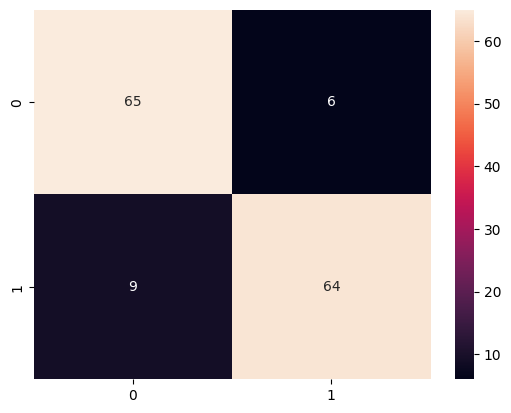

In [ ]:
#confusion matrix dan classificatio report
print(classification_report(y_test, y_prediksi))
sb.heatmap(confusion_matrix(y_test, y_prediksi),annot=True)

In [ ]:
n_akurasi = []
for k in range (1,30):
    y_prediksi = ensemble_model.predict(x_test)
    akurasi = accuracy_score(y_test,y_prediksi)
    n_akurasi.append(akurasi)
print(n_akurasi)

[0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334, 0.8958333333333334]


**EVALUASI DENGAN ROC CURVE**

In [ ]:
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

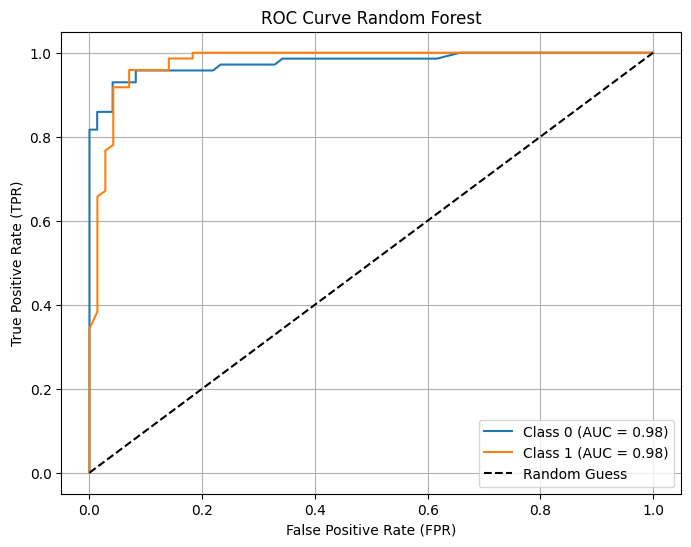

In [ ]:
# Misalkan model adalah untuk klasifikasi multiclass (2 kelas)
y_prob = rf_model.predict_proba(x_test)  # Shape: (n_samples, n_classes)

# Hitung ROC untuk setiap kelas
n_classes = y_prob.shape[1]  # Jumlah kelas

plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, i], pos_label=i)
    # Fix: Calculate AUC score for each class separately
    auc_score = roc_auc_score(y_test == i, y_prob[:, i])
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {auc_score:.2f})')

# Garis tebak acak (diagonal)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Labeling dan penambahan grid
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Random Forest')
plt.legend(loc='best')
plt.grid()
plt.show()



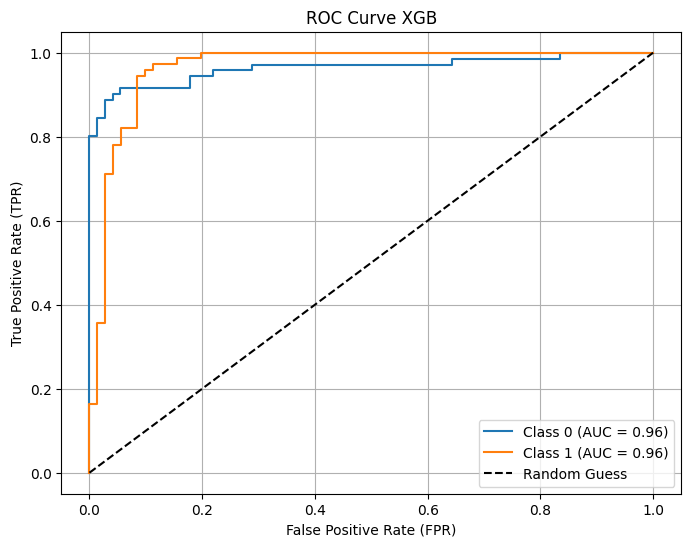

In [ ]:
# Misalkan model adalah untuk klasifikasi multiclass (2 kelas)
y_prob = xgb_model.predict_proba(x_test)  # Shape: (n_samples, n_classes)

# Hitung ROC untuk setiap kelas
n_classes = y_prob.shape[1]  # Jumlah kelas

plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, i], pos_label=i)
    # Fix: Calculate AUC score for each class separately
    auc_score = roc_auc_score(y_test == i, y_prob[:, i])
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {auc_score:.2f})')

# Garis tebak acak (diagonal)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Labeling dan penambahan grid
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve XGB')
plt.legend(loc='best')
plt.grid()
plt.show()



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [07:13:05] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


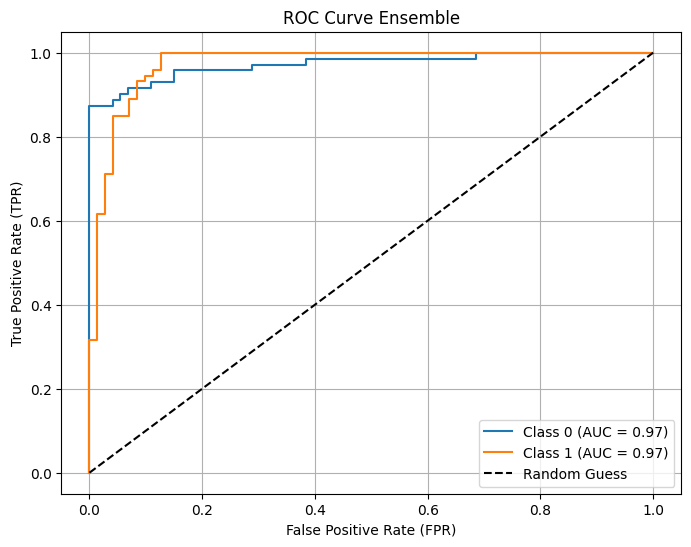

In [ ]:


ensemble_model = VotingClassifier(estimators=[('rf', rf_model), ('xgb', xgb_model)], voting='soft')
ensemble_model.fit(x_train, y_train)
y_prob = ensemble_model.predict_proba(x_test)  # Shape: (n_samples, n_classes)
# Hitung ROC untuk setiap kelas
n_classes = y_prob.shape[1]  # Jumlah kelas

plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, i], pos_label=i)
    # Fix: Calculate AUC score for each class separately
    auc_score = roc_auc_score(y_test == i, y_prob[:, i])
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {auc_score:.2f})')

# Garis tebak acak (diagonal)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Labeling dan penambahan grid
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Ensemble')
plt.legend(loc='best')
plt.grid()
plt.show()


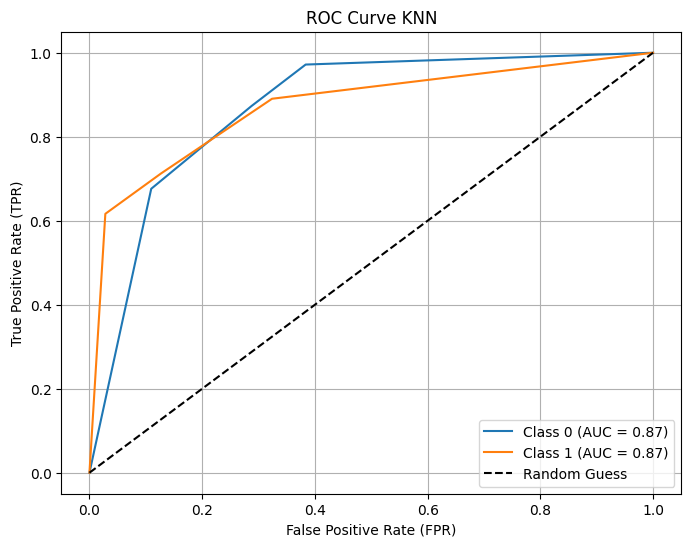

In [ ]:

y_prob = knn.predict_proba(x_test)  # Shape: (n_samples, n_classes)

# Hitung ROC untuk setiap kelas
n_classes = y_prob.shape[1]  # Jumlah kelas

plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, i], pos_label=i)
    # Fix: Calculate AUC score for each class separately
    auc_score = roc_auc_score(y_test == i, y_prob[:, i])
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {auc_score:.2f})')

# Garis tebak acak (diagonal)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Labeling dan penambahan grid
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve KNN')
plt.legend(loc='best')
plt.grid()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train) # Changed from X_train to x_train
X_test_scaled = scaler.transform(x_test)   # Changed from X_test to x_test

# Simpan model dan scaler
joblib.dump(rf_model, 'rf_model.pkl')
#joblib.dump(xgb_model, 'xgb_model.pkl')
#joblib.dump(knn, 'knn.pkl')
#joblib.dump(ensemble_model, 'ensemble_model.pkl')
joblib.dump(scaler, 'scaler_rf_embrio.pkl')

['scaler_rf_embrio.pkl']

In [ ]:
# prompt: bagaimana cara memesukan preprocessingnya untuk data dari luar?

def preprocess_external_image(image_path, scaler_path, model_path):
  """
  Loads an external image, preprocesses it, extracts features, scales them,
  and predicts the class using a saved model.

  Args:
    image_path (str): The path to the external image file.
    scaler_path (str): The path to the saved scaler object (.pkl).
    model_path (str): The path to the saved model object (.pkl).

  Returns:
    int or None: The predicted class label (0 or 1) if successful, None otherwise.
  """
  try:
    # Load the image
    gbr_read = cv2.imread(image_path)
    if gbr_read is None:
      print(f"Error: Could not read image from {image_path}")
      return None

    # Preprocessing and Feature Extraction (same as in the provided code)
    rataR = []
    rataG = []
    rataB = []
    rataH = []
    rataS = []
    rataV = []
    ratagray = []
    stand = []
    luas = []
    perimeter = []
    contrast = []
    dissimilarity = []
    homogeneity = []
    energy = []
    correlation = []

    gbr_rgb = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2RGB)
    (R, G, B) = cv2.split(gbr_rgb)
    meanR = np.mean(R)
    rataR.append(meanR)
    meanG = np.mean(G)
    rataG.append(meanG)
    meanB = np.mean(B)
    rataB.append(meanB)

    gbr_hsv = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2HSV)
    H = gbr_hsv[:, :, 0]
    S = gbr_hsv[:, :, 1]
    V = gbr_hsv[:, :, 2]
    meanH = np.mean(H)
    rataH.append(meanH)
    meanS = np.mean(S)
    rataS.append(meanS)
    meanV = np.mean(V)
    rataV.append(meanV)

    gbr_gray = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2GRAY)
    rata = np.mean(gbr_gray)
    ratagray.append(rata)
    standar = np.std(gbr_gray)
    stand.append(standar)

    # Ekstraksi Fitur Bentuk
    _, thresh = cv2.threshold(gbr_gray, 127, 255, 0)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contours) > 0:
        contour = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(contour)
        perimeter_val = cv2.arcLength(contour, True)
    else:
        area = 0
        perimeter_val = 0

    luas.append(area)
    perimeter.append(perimeter_val)

    # Ekstraksi Fitur Tekstur (GLCM)
    glcm = graycomatrix(gbr_gray, [1], [0], 256, symmetric=True, normed=True)
    contrast_val = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity_val = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogeneity_val = graycoprops(glcm, 'homogeneity')[0, 0]
    energy_val = graycoprops(glcm, 'energy')[0, 0]
    correlation_val = graycoprops(glcm, 'correlation')[0, 0]

    contrast.append(contrast_val)
    dissimilarity.append(dissimilarity_val)
    homogeneity.append(homogeneity_val)
    energy.append(energy_val)
    correlation.append(correlation_val)

    # Create a DataFrame for the extracted features
    external_data = pd.DataFrame({
        'Mean-R': rataR, 'Mean-G': rataG, 'Mean-B': rataB,
        'Mean-H': rataH, 'Mean-V': rataV, 'Mean-s': rataS,
        'Mean-Gray': ratagray, 'Standar-Deviasi': stand,
        'Luas': luas, 'Perimeter': perimeter, 'Contrast': contrast,
        'Dissimilarity': dissimilarity, 'Homogeneity': homogeneity,
        'Energy': energy, 'Correlation': correlation
    })

    # Load the saved scaler
    try:
      scaler = joblib.load(scaler_path)
    except FileNotFoundError:
      print(f"Error: Scaler file not found at {scaler_path}")
      return None

    # Scale the features
    scaled_features = scaler.transform(external_data)

    # Load the saved model
    try:
      model = joblib.load(model_path)
    except FileNotFoundError:
      print(f"Error: Model file not found at {model_path}")
      return None

    # Make a prediction
    prediction = model.predict(scaled_features)

    return prediction[0] # Return the predicted class label

  except Exception as e:
    print(f"An error occurred during preprocessing and prediction: {e}")
    return None


# external_image_path = '/content/drive/MyDrive/path/to/your/external_image.jpg'
# saved_scaler_path = '/content/drive/MyDrive/scaler_rf_embrio.pkl'
# saved_model_path = '/content/drive/MyDrive/ensemble_model.pkl'

# predicted_class = preprocess_external_image(external_image_path, saved_scaler_path, saved_model_path)

# if predicted_class is not None:
#   if predicted_class == 0:
#     print("The image is classified as 'good'.")
#   elif predicted_class == 1:
#     print("The image is classified as 'not good'.")
# else:
#   print("Preprocessing and prediction failed.")


In [ ]:
import joblib

# Load model dan scaler
model = joblib.load('rf_model.pkl')
scaler = joblib.load('scaler_rf_embrio.pkl')

# Panggil fungsi untuk prediksi dengan upload gambar
predict_uploaded_image(model, scaler)

Saving Day-5-Embryo.jpg to Day-5-Embryo.jpg
Citra yang diunggah: Day-5-Embryo.jpg
Hasil prediksi untuk Day-5-Embryo.jpg: Embrio Not Good Embrio


In [ ]:

from google.colab import files
import io

image_path = ""

def extract_features_single_image(image_path):
    try:
        gbr_read = cv2.imread(image_path)
        if gbr_read is None:
            print(f"Error: Tidak bisa membaca citra dari {image_path}")
            return None

        # Ekstraksi Fitur Warna
        gbr_rgb = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2RGB)
        (R, G, B) = cv2.split(gbr_rgb)
        meanR = np.mean(R)
        meanG = np.mean(G)
        meanB = np.mean(B)

        gbr_hsv = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2HSV)
        H = gbr_hsv[:, :, 0]
        S = gbr_hsv[:, :, 1]
        V = gbr_hsv[:, :, 2]
        meanH = np.mean(H)
        meanS = np.mean(S)
        meanV = np.mean(V)

        gbr_gray = cv2.cvtColor(gbr_read, cv2.COLOR_BGR2GRAY)
        ratagray = np.mean(gbr_gray)
        standar = np.std(gbr_gray)

        # Ekstraksi Fitur Bentuk
        _, thresh = cv2.threshold(gbr_gray, 127, 255, 0)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        if len(contours) > 0:
            contour = max(contours, key=cv2.contourArea)
            area = cv2.contourArea(contour)
            perimeter_val = cv2.arcLength(contour, True)
        else:
            area = 0
            perimeter_val = 0

        # Ekstraksi Fitur Tekstur (GLCM)
        # Pastikan citra abu-abu memiliki tipe data uint8 sebelum GLCM
        gbr_gray_uint8 = gbr_gray.astype(np.uint8)
        glcm = graycomatrix(gbr_gray_uint8, [1], [0], 256, symmetric=True, normed=True)
        contrast_val = graycoprops(glcm, 'contrast')[0, 0]
        dissimilarity_val = graycoprops(glcm, 'dissimilarity')[0, 0]
        homogeneity_val = graycoprops(glcm, 'homogeneity')[0, 0]
        energy_val = graycoprops(glcm, 'energy')[0, 0]
        correlation_val = graycoprops(glcm, 'correlation')[0, 0]

        features = np.array([
            meanR, meanG, meanB, meanH, meanV, meanS, ratagray, standar,
            area, perimeter_val, contrast_val, dissimilarity_val, homogeneity_val,
            energy_val, correlation_val
        ])
        return features.reshape(1, -1) # Mengembalikan sebagai 2D array untuk scaler

    except Exception as e:
        print(f"Error saat mengekstraksi fitur: {e}")
        return None


def predict_uploaded_image(model, scaler):

    uploaded = files.upload()

    for filename in uploaded.keys():
        print(f'Citra yang diunggah: {filename}')
        # Simpan citra yang diunggah ke file sementara
        with open(filename, 'wb') as f:
            f.write(uploaded[filename])

        # Ekstraksi fitur dari citra yang diunggah
        features = extract_features_single_image(filename)

        if features is not None:
            # Lakukan penskalaan fitur
            scaled_features = scaler.transform(features)

            # Lakukan prediksi menggunakan model yang sudah dilatih
            prediction = model.predict(scaled_features)

            predicted_label = "Good embrio" if prediction[0] == 0 else "Not Good Embrio"

            print(f"Hasil prediksi untuk {filename}: Embrio {predicted_label}")
        else:
            print(f"Gagal mengekstrak fitur dari {filename}. Tidak bisa melakukan prediksi.")

